<a href="https://colab.research.google.com/github/ss3299952-cmd/cricket-probablity/blob/main/day9_model_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
files = os.listdir("/content/ipl_data")
print(len(files))
print(files[:5])

FileNotFoundError: [Errno 2] No such file or directory: '/content/ipl_data'

In [ ]:
import json
import pandas as pd
with open("/content/ipl_data/1136574.json") as f:
  match =json.load(f)

print(match.keys())
print(match["info"]["teams"])
print(match["info"].get("venue"))
print(match["info"].get("toss"))
print(match["info"].get("outcome"))

dict_keys(['meta', 'info', 'innings'])
['Mumbai Indians', 'Royal Challengers Bangalore']
Wankhede Stadium
{'decision': 'field', 'winner': 'Royal Challengers Bangalore'}
{'winner': 'Mumbai Indians', 'by': {'runs': 46}}


In [ ]:
rows = []
for inn_no, inn in enumerate(match["innings"], start = 1):
  for over in inn["overs"]:
    for ball in over ["deliveries"]:
      rows.append({
          "innings" : inn_no,
          "team" : inn["team"],
          "over" : over["over"],
          "batter" : ball["batter"],
          "bowler" : ball["bowler"],
          "runs_batter" : ball["runs"]["batter"],
          "runs_extra" : ball["runs"]["extras"],
          "runs_total" : ball["runs"]["total"],
          "wickets" : 1 if "wickets" in ball else 0,
      })
      df = pd.DataFrame(rows)
      df.head()

In [ ]:
df.shape

(251, 9)

In [ ]:
df.info()

In [ ]:
df["team"].unique()

array(['Mumbai Indians', 'Royal Challengers Bangalore'], dtype=object)

In [ ]:
df["batter"].nunique()
df[["batter" , "runs_batter"]]

,batter,runs_batter
0,SA Yadav,0
1,Ishan Kishan,0
2,RG Sharma,0
3,E Lewis,1
4,RG Sharma,1
...,...,...
246,V Kohli,4
247,V Kohli,0
248,V Kohli,6
249,V Kohli,0


In [ ]:
inn1 = df[df["innings"] == 1]
inn1.shape

(127, 9)

In [ ]:
w = df[df["wickets"] == 1]
w[["innings" , "over","batter" , "bowler"]]

,innings,over,batter,bowler
0,1,0,SA Yadav,UT Yadav
1,1,0,Ishan Kishan,UT Yadav
69,1,11,E Lewis,CJ Anderson
95,1,15,RG Sharma,CJ Anderson
113,1,18,KA Pollard,CR Woakes
124,1,19,RG Sharma,CJ Anderson
152,2,4,Q de Kock,MJ McClenaghan
155,2,4,AB de Villiers,MJ McClenaghan
186,2,9,Mandeep Singh,KH Pandya
187,2,9,CJ Anderson,KH Pandya


In [ ]:
df[(df["innings"] == 2) & (df["runs_batter"] >= 4)]

NameError: name 'df' is not defined

In [ ]:
df.groupby("team")["runs_total"].sum()

,runs_total
team,
Mumbai Indians,213
Royal Challengers Bangalore,167


In [ ]:
top_bat = df.groupby("batter")["runs_batter"].sum()
top_bat = top_bat.sort_values(ascending=False)
top_bat.head(5)

,runs_batter
batter,
RG Sharma,94
V Kohli,92
E Lewis,65
Q de Kock,19
HH Pandya,17


In [ ]:
bw = df.groupby("bowler")["wickets"].sum()
bw.sort_values(ascending=False).head(5)

,wickets
bowler,
CJ Anderson,3
KH Pandya,3
MJ McClenaghan,2
JJ Bumrah,2
UT Yadav,2


In [ ]:
df.groupby(["innings", "over"]) ["runs_total"].sum()

innings  over
1        0        3
         1       12
         2        6
         3       19
         4       16
         5        4
         6        3
         7       13
         8        9
         9       10
         10      13
         11       6
         12       4
         13      10
         14      15
         15      10
         16      13
         17      11
         18      15
         19      21
2        0        7
         1       13
         2        7
         3       13
         4        4
         5       11
         6        4
         7        6
         8        5
         9        6
         10       8
         11       3
         12       7
         13      10
         14       4
         15      13
         16      13
         17       3
         18      18
         19      12
Name: runs_total, dtype: int64

In [ ]:
runs = df.groupby("batter")["runs_batter"].sum().reset_index()
runs

,batter,runs_batter
0,AB de Villiers,1
1,CJ Anderson,0
2,CR Woakes,11
3,E Lewis,65
4,HH Pandya,17
5,Ishan Kishan,0
6,KA Pollard,5
7,KH Pandya,15
8,MJ McClenaghan,0
9,Mandeep Singh,16


In [ ]:
deliveries = df.groupby("batter").size().reset_index(name="deliveries")
deliveries

,batter,deliveries
0,AB de Villiers,2
1,CJ Anderson,1
2,CR Woakes,11
3,E Lewis,44
4,HH Pandya,5
5,Ishan Kishan,1
6,KA Pollard,8
7,KH Pandya,13
8,MJ McClenaghan,1
9,Mandeep Singh,16


In [ ]:
bat = runs.merge(deliveries, on="batter")
bat["runs_per_delivery"] = bat["runs_batter"] / bat["deliveries"]
bat.sort_values("runs_per_delivery", ascending=False).head(5)

,batter,runs_batter,deliveries,runs_per_delivery
4,HH Pandya,17,5,3.400000
10,Mohammed Siraj,8,3,2.666667
12,RG Sharma,94,54,1.740741
16,V Kohli,92,62,1.483871
3,E Lewis,65,44,1.477273


In [ ]:
x = df.groupby(["innings","over"])["runs_total"].sum().reset_index()
x.sort_values("runs_total" , ascending=False).head(3)


,innings,over,runs_total
19,1,19,21
3,1,3,19
38,2,18,18


In [ ]:
import glob, zipfile
for z in glob.glob("/content/*.zip"):
    with zipfile.ZipFile(z) as f:
        n_json = sum(n.endswith(".json") for n in f.namelist())
        print(z, "| json:", n_json)
        if n_json > 100:
            f.extractall("/content/ipl_data")

print(len(glob.glob("/content/ipl_data/**/*.json", recursive=True)))

0


In [ ]:
import glob, json
from collections import Counter

files = sorted(glob.glob("/content/ipl_data/**/*.json", recursive=True))
in_files = Counter()
failed = Counter()
errors = {}
for f in files:
    try:
        with open(f) as fh:
            m = json.load(fh)
        year = m["info"]["dates"][0][:4]
    except Exception as e:
        failed["unreadable"] += 1
        errors.setdefault("unreadable", repr(e))
        continue
    in_files[year] += 1
    try:
        for inn in m.get("innings", []):
            inn["team"]
            for over in inn["overs"]:
                for ball in over["deliveries"]:
                    ball["batter"]
                    ball["bowler"]
                    ball["runs"]["batter"]
                    ball["runs"]["extras"]
                    ball["runs"]["total"]
    except Exception as e:
        failed[year] += 1
        errors.setdefault(year, repr(e))

print("Matches per year in files:", sorted(in_files.items()))
print("Failed per year:", sorted(failed.items()))
print("First error per year:", errors)

Matches per year in files: []
Failed per year: []
First error per year: {}


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
all_df = pd.read_csv("/content/ipl_all_balls.csv")
all_df.shape

/tmp/ipykernel_588/2472296343.py:3: DtypeWarning: Columns (1,7) have mixed types. Specify dtype option on import or set low_memory=False.
  all_df = pd.read_csv("/content/ipl_all_balls.csv")


(277183, 21)

In [ ]:
g = all_df.groupby(["match_id", "innings", "over"])["runs_total"]
per_over = g.sum().reset_index()
per_over.head()

,match_id,innings,over,runs_total
0,335982,1,0,3
1,335982,1,1,18
2,335982,1,2,6
3,335982,1,3,23
4,335982,1,4,10


In [ ]:
avg_over = per_over.groupby(["innings", "over"])["runs_total"].mean()
avg_over = avg_over.unstack("innings")
avg_over.index = avg_over.index + 1
avg_over.round(1)

NameError: name 'per_over' is not defined

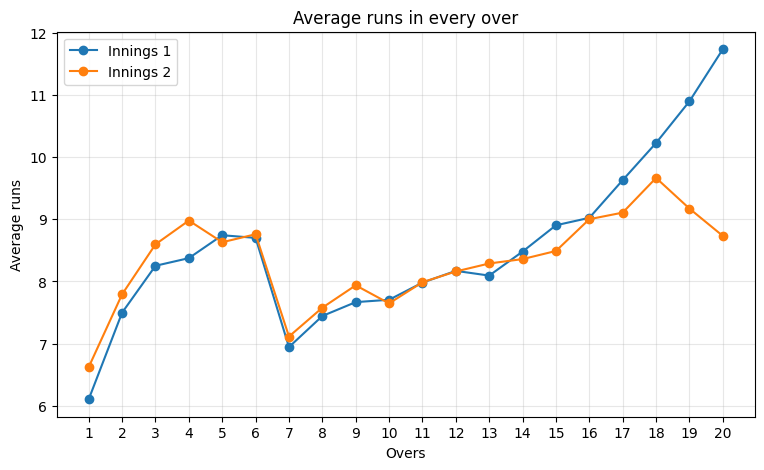

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(avg_over.index, avg_over[1], marker="o", label="Innings 1")
plt.plot(avg_over.index, avg_over[2], marker="o", label="Innings 2")
plt.title("Average runs in every over")
plt.xlabel("Overs")
plt.ylabel("Average runs")
plt.xticks(range(1, 21))
plt.grid(alpha=0.3)
plt.legend()
plt.savefig("chart1_runs_per_over.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
w = all_df[all_df["wickets"] > 0]
real_w = w[w["wicket_kind"] != "retired hurt"]
n_matches = all_df["match_id"].nunique()
w_over = real_w.groupby("over")["wickets"].sum() / n_matches
w_over.index = w_over.index + 1
w_over.round(2)

,wickets
over,
1,0.40
2,0.46
3,0.51
4,0.49
5,0.53
6,0.48
7,0.41
8,0.44
9,0.49


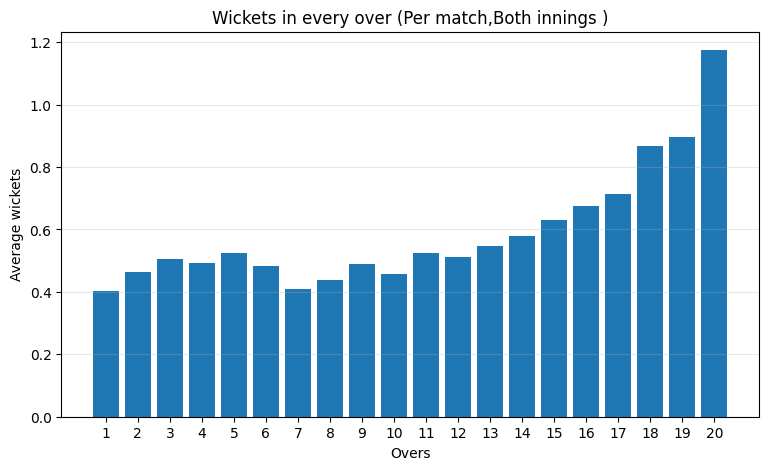

In [ ]:
plt.figure(figsize=(9, 5))
plt.bar(w_over.index, w_over.values)
plt.title("Wickets in every over (Per match,Both innings )")
plt.xlabel("Overs")
plt.ylabel("Average wickets")
plt.xticks(range(1, 21))
plt.grid(axis="y", alpha=0.3)
plt.savefig("chart2_wickets_per_over.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
inn1 = all_df[all_df["innings"] == 1]
g = inn1.groupby(["year", "match_id"])["runs_total"]
per_match = g.sum().reset_index()
avg_year = per_match.groupby("year")["runs_total"].mean()
avg_year.round(1)

,runs_total
year,
2008,161.0
2009,150.3
2010,164.8
2011,152.4
2012,157.5
2013,155.9
2014,163.1
2015,166.3
2016,162.6


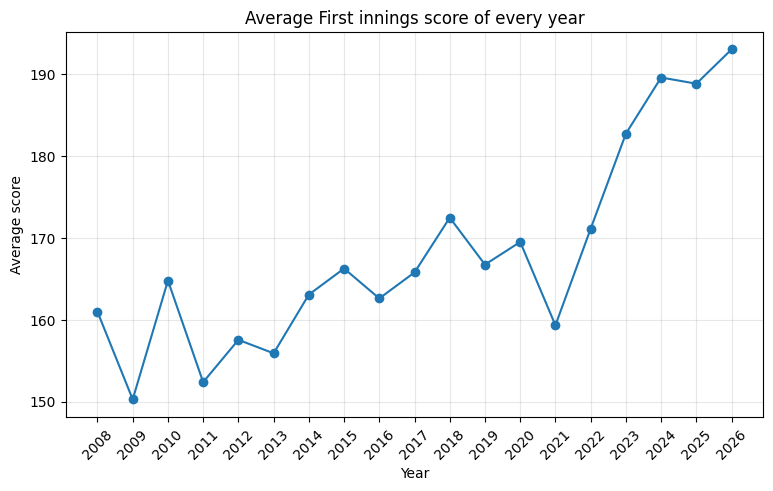

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(avg_year.index, avg_year.values, marker="o")
plt.title("Average First innings score of every year")
plt.xlabel("Year")
plt.ylabel("Average score")
plt.xticks(avg_year.index, rotation=45)
plt.grid(alpha=0.3)
plt.savefig("chart3_avg_score_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
cols = ["match_id", "year", "toss_decision"]
toss_df = all_df.drop_duplicates("match_id")[cols]
share = pd.crosstab(toss_df["year"], toss_df["toss_decision"],
                    normalize="index") * 100
share.round(0)

toss_decision,bat,field
year,,
2008,45.0,55.0
2009,61.0,39.0
2010,65.0,35.0
2011,34.0,66.0
2012,50.0,50.0
2013,59.0,41.0
2014,32.0,68.0
2015,42.0,58.0
2016,18.0,82.0


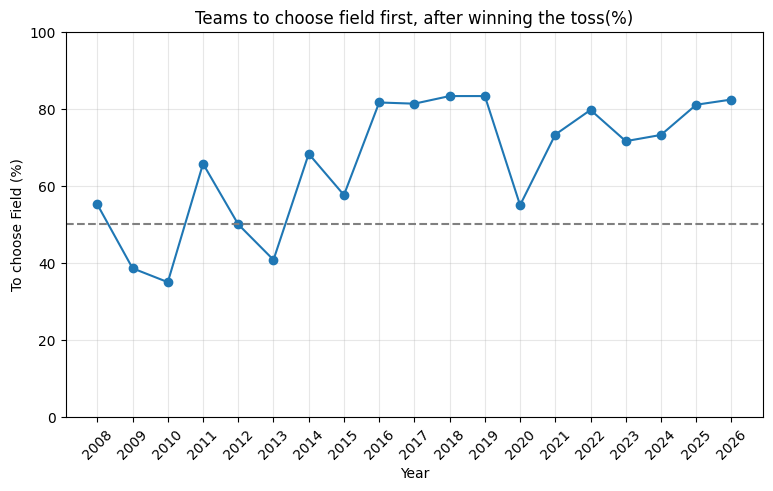

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(share.index, share["field"], marker="o")
plt.axhline(50, linestyle="--", color="gray")
plt.ylim(0, 100)
plt.title("Teams to choose field first, after winning the toss(%)")
plt.xlabel("Year")
plt.ylabel("To choose Field (%)")
plt.xticks(share.index, rotation=45)
plt.grid(alpha=0.3)
plt.savefig("chart4_toss_field_share.png", dpi=150, bbox_inches="tight")
plt.show()

Chart 1 : The 20th over is the highest-scoring over for the team batting first, averaging 11.7 runs. Teams bat most aggressively in the death overs to finish with a big total. The second innings averages 8.7 in the same over, but that only counts chases that were still alive in the final over, so the two numbers are not a like-for-like comparison.
Chart 2: Wickets per over
Wickets fall at a steady 0.4 to 0.5 per over (per match, both innings) through the first 12 overs, then rise steadily. The 20th over has the most wickets (about 1.17), followed by overs 19 and 18 (about 0.85 each). Batters take more risks in the death overs to maximise runs, and that costs wickets. Combined with Chart 1, the final over is both the highest-scoring and the highest-risk over.
Chart 3: Average 1st innings score by year
The average first-innings score rose from about 150 to 165 in the early seasons to about 193 in 2026. The sharpest jump came after 2021 (about 158 in 2021 to about 180 in 2023). The lowest average was in 2009 (about 150). This may be linked to more aggressive batting and the Impact Player rule introduced in 2023, but this data alone cannot prove the cause.

Chart 4: Teams choosing to field after winning the toss
In the early seasons teams were split on the toss decision, and in 2009, 2010 and 2013 most captains chose to bat first (field was only about 35 to 41 percent). From 2014 onwards, fielding first became the clear preference, peaking at about 80 percent in 2018 and 2019 and staying around 70 to 77 percent in recent seasons (2020 is the exception, at about 54 percent). Teams clearly believe chasing is the better option, but this chart alone cannot show whether chasing actually wins more. That is what the toss analysis will test.

In [ ]:
import os
from google.colab import drive

drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/cricket_project"
os.makedirs(FOLDER, exist_ok=True)

all_df.to_csv(FOLDER + "/ipl_all_balls_v2.csv", index=False)
print(os.listdir(FOLDER))

Mounted at /content/drive
['ipl_all_balls_v2.csv']


In [ ]:
import os
from google.colab import drive

drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/cricket_project"
os.makedirs(FOLDER, exist_ok=True)

all_df.to_csv(FOLDER + "/ipl_all_balls_v2.csv", index=False)
print(os.listdir(FOLDER))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['ipl_all_balls_v2.csv']


In [ ]:
print(all_df.shape)
print("is_legal" in all_df.columns, "target_overs" in all_df.columns)

(295557, 21)
False False


In [ ]:
import os, json, glob
import pandas as pd

def load_match_v2(path):
    with open(path) as f:
        match = json.load(f)
    info = match["info"]
    toss = info.get("toss", {})
    outcome = info.get("outcome", {})
    dates = info.get("dates", [None])
    base = {
        "match_id": os.path.basename(path).replace(".json", ""),
        "season": info.get("season"),
        "date": dates[0],
        "venue": info.get("venue"),
        "toss_winner": toss.get("winner"),
        "toss_decision": toss.get("decision"),
        "winner": outcome.get("winner"),
        "result": outcome.get("result"),
    }
    rows = []
    for inn_no, inn in enumerate(match.get("innings", []), start=1):
        if inn.get("super_over"):
            continue
        target = inn.get("target", {})
        for over in inn["overs"]:
            for ball in over["deliveries"]:
                wk = ball.get("wickets", [])
                ex = ball.get("extras", {})
                legal = 0 if ("wides" in ex or "noballs" in ex) else 1
                row = dict(base)
                row.update({
                    "innings": inn_no,
                    "team": inn["team"],
                    "target_runs": target.get("runs"),
                    "target_overs": target.get("overs"),
                    "over": over["over"],
                    "batter": ball["batter"],
                    "bowler": ball["bowler"],
                    "runs_batter": ball["runs"]["batter"],
                    "runs_extra": ball["runs"]["extras"],
                    "runs_total": ball["runs"]["total"],
                    "is_legal": legal,
                    "wickets": len(wk),
                    "player_out": wk[0]["player_out"] if wk else None,
                    "wicket_kind": wk[0]["kind"] if wk else None,
                })
                rows.append(row)
    return pd.DataFrame(rows)

files = sorted(glob.glob("/content/ipl_data/**/*.json", recursive=True))
print("files:", len(files))

frames = []
bad = []
for f in files:
    try:
        frames.append(load_match_v2(f))
    except Exception as e:
        bad.append((f, str(e)))

all_df = pd.concat(frames, ignore_index=True)
all_df["date"] = pd.to_datetime(all_df["date"])
all_df["year"] = all_df["date"].dt.year
print("shape:", all_df.shape)
print("failed:", len(bad))
print("is_legal" in all_df.columns, "target_overs" in all_df.columns)

per_year = all_df.drop_duplicates("match_id")["year"].value_counts().sort_index()
assert set(range(2008, 2027)).issubset(per_year.index), "A year is missing!"
print("Year check passed")

FOLDER = "/content/drive/MyDrive/cricket_project"
all_df.to_csv(FOLDER + "/ipl_all_balls_v2.csv", index=False)
print("saved:", os.listdir(FOLDER))

files: 1243


/tmp/ipykernel_909/1930847298.py:62: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  all_df = pd.concat(frames, ignore_index=True)


shape: (295557, 23)
failed: 0
True True
Year check passed
saved: ['ipl_all_balls_v2.csv']


In [ ]:
c = all_df[all_df["innings"] == 2].copy()
c["target_overs"] = pd.to_numeric(c["target_overs"], errors="coerce")
print(c["match_id"].nunique())
c = c[c["target_overs"] == 20]
c = c.dropna(subset=["winner", "target_runs"])
print(c["match_id"].nunique())

1237
1185


In [ ]:
c["is_wicket"] = ((c["wickets"] > 0) &                  (c["wicket_kind"] != "retired hurt")).astype(int)
g = c.groupby("match_id")
c["cum_runs"] = g["runs_total"].cumsum()
c["cum_wkts"] = g["is_wicket"].cumsum()
c["balls_bowled"] = g["is_legal"].cumsum()
c[["match_id", "over", "runs_total", "cum_runs", "balls_bowled"]].head(8)

,match_id,over,runs_total,cum_runs,balls_bowled
125,1082591,0,1,1,1
126,1082591,0,0,1,2
127,1082591,0,0,1,3
128,1082591,0,2,3,4
129,1082591,0,4,7,5
130,1082591,0,4,11,6
131,1082591,1,0,11,7
132,1082591,1,0,11,8


In [ ]:
c["runs_left"] = c["target_runs"] - c["cum_runs"]
c["balls_left"] = 120 - c["balls_bowled"]
c["wickets_left"] = 10 - c["cum_wkts"]
crr = c["cum_runs"] * 6 / c["balls_bowled"]
c["crr"] = crr.where(c["balls_bowled"] > 0, 0)

In [ ]:
c["chasing_won"] = (c["team"] == c["winner"]).astype(int)
c["chaser_won_toss"] = (c["team"] == c["toss_winner"]).astype(int)
live = ((c["runs_left"] > 0) & (c["balls_left"] > 0) &        (c["wickets_left"] > 0))
chase_df = c[live].copy()
chase_df["rrr"] = chase_df["runs_left"] * 6 / chase_df["balls_left"]
chase_df.shape

(136708, 34)

In [ ]:
keep = ["match_id", "year", "venue", "team", "toss_winner",        "toss_decision", "chaser_won_toss", "over", "batter", "bowler",        "player_out", "wicket_kind", "runs_total", "is_wicket",        "target_runs", "runs_left", "balls_left", "wickets_left",        "crr", "rrr", "chasing_won"]
chase_df = chase_df[keep].reset_index(drop=True)
chase_df.head()

,match_id,year,venue,team,toss_winner,toss_decision,chaser_won_toss,over,batter,bowler,...,wicket_kind,runs_total,is_wicket,target_runs,runs_left,balls_left,wickets_left,crr,rrr,chasing_won
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,CH Gayle,A Nehra,...,None,1,0,208.0,207.0,119,10,6.0,10.436975,0
1,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,None,0,0,208.0,207.0,118,10,3.0,10.525424,0
2,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,None,0,0,208.0,207.0,117,10,2.0,10.615385,0
3,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,None,2,0,208.0,205.0,116,10,4.5,10.603448,0
4,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,None,4,0,208.0,201.0,115,10,8.4,10.486957,0


In [ ]:
print(chase_df["match_id"].nunique())
chase_df.isna().sum()

1185


,0
match_id,0
year,0
venue,0
team,0
toss_winner,0
toss_decision,0
chaser_won_toss,0
over,0
batter,0
bowler,0


In [ ]:
cols = ["runs_left", "balls_left", "wickets_left", "crr", "rrr"]
chase_df[cols].describe().round(2)

,runs_left,balls_left,wickets_left,crr,rrr
count,136708.00,136708.00,136708.00,136708.00,136708.00
mean,96.58,63.24,7.52,7.85,10.96
std,51.67,33.11,2.14,2.55,13.18
min,1.00,1.00,1.00,0.00,0.08
25%,56.00,35.00,6.00,6.51,7.40
50%,95.00,64.00,8.00,7.79,9.16
75%,135.00,92.00,9.00,9.16,11.38
max,287.00,120.00,10.00,60.00,792.00


In [ ]:
g = chase_df.groupby("match_id")
print((g["runs_left"].diff().dropna() <= 0).all())
print((g["balls_left"].diff().dropna() <= 0).all())

True
True


In [ ]:
first = chase_df["match_id"].iloc[0]
m1 = chase_df[chase_df["match_id"] == first]
cols = ["over", "runs_left", "balls_left", "wickets_left","rrr", "chasing_won"]
m1[cols].head(10)

,over,runs_left,balls_left,wickets_left,rrr,chasing_won
0,0,207.0,119,10,10.436975,0
1,0,207.0,118,10,10.525424,0
2,0,207.0,117,10,10.615385,0
3,0,205.0,116,10,10.603448,0
4,0,201.0,115,10,10.486957,0
5,0,197.0,114,10,10.368421,0
6,1,197.0,113,10,10.460177,0
7,1,197.0,112,10,10.553571,0
8,1,196.0,111,10,10.594595,0
9,1,196.0,110,10,10.690909,0


In [ ]:
per_match = chase_df.drop_duplicates("match_id")
print(per_match["chasing_won"].mean())
print(per_match["chaser_won_toss"].mean())
print(chase_df["chasing_won"].mean())

0.5451476793248945
0.6624472573839663
0.5249583052930333


In [ ]:
chase_df.to_csv("/content/chase_df.csv", index=False)

In [ ]:
print(chase_df["chasing_won"].value_counts(normalize=True).round(3))
print("matches:", chase_df["match_id"].nunique())
chase_df.groupby("match_id").size().describe().round(1)

chasing_won
1    0.525
0    0.475
Name: proportion, dtype: float64
matches: 1185


,0
count,1185.0
mean,115.4
std,12.8
min,37.0
25%,112.0
50%,120.0
75%,123.0
max,135.0


In [ ]:
by_year = chase_df.drop_duplicates("match_id")["year"]
by_year.value_counts().sort_index()

,count
year,
2008,54
2009,53
2010,59
2011,69
2012,73
2013,73
2014,57
2015,52
2016,56


In [ ]:
tr, te = train_test_split(chase_df, test_size=0.2, random_state=42)
shared = set(tr["match_id"]) & set(te["match_id"])
print("matches in test:", te["match_id"].nunique())
print("of these, also in train:", len(shared))

matches in test: 1185
of these, also in train: 1185


In [ ]:
import os
import pandas as pd
from sklearn.model_selection import train_test_split
from google.colab import drive
drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/cricket_project"
chase_df = pd.read_csv(FOLDER + "/chase_df.csv")
print(chase_df.shape)
chase_df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(136708, 21)


,match_id,year,venue,team,toss_winner,toss_decision,chaser_won_toss,over,batter,bowler,...,wicket_kind,runs_total,is_wicket,target_runs,runs_left,balls_left,wickets_left,crr,rrr,chasing_won
0,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,CH Gayle,A Nehra,...,NaN,1,0,208.0,207.0,119,10,6.0,10.436975,0
1,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,NaN,0,0,208.0,207.0,118,10,3.0,10.525424,0
2,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,NaN,0,0,208.0,207.0,117,10,2.0,10.615385,0
3,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,NaN,2,0,208.0,205.0,116,10,4.5,10.603448,0
4,1082591,2017,"Rajiv Gandhi International Stadium, Uppal",Royal Challengers Bangalore,Royal Challengers Bangalore,field,1,0,Mandeep Singh,A Nehra,...,NaN,4,0,208.0,201.0,115,10,8.4,10.486957,0


In [ ]:
import os
print(os.listdir("/content/drive/MyDrive/cricket_project"))

['ipl_all_balls_v2.csv']


In [ ]:
import os
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/cricket_project"
all_df = pd.read_csv(FOLDER + "/ipl_all_balls_v2.csv")
print("all_df:", all_df.shape)

# only 2nd innings, full 20-over chases, winner known
c = all_df[all_df["innings"] == 2].copy()
c["target_overs"] = pd.to_numeric(c["target_overs"], errors="coerce")
print("matches with 2nd innings:", c["match_id"].nunique())
c = c[c["target_overs"] == 20]
c = c.dropna(subset=["winner", "target_runs"])
print("after filter:", c["match_id"].nunique())

# running totals inside each match
c["is_wicket"] = ((c["wickets"] > 0) &
                  (c["wicket_kind"] != "retired hurt")).astype(int)
g = c.groupby("match_id")
c["cum_runs"] = g["runs_total"].cumsum()
c["cum_wkts"] = g["is_wicket"].cumsum()
c["balls_bowled"] = g["is_legal"].cumsum()

# match situation
c["runs_left"] = c["target_runs"] - c["cum_runs"]
c["balls_left"] = 120 - c["balls_bowled"]
c["wickets_left"] = 10 - c["cum_wkts"]
crr = c["cum_runs"] * 6 / c["balls_bowled"]
c["crr"] = crr.where(c["balls_bowled"] > 0, 0)

# label and toss column
c["chasing_won"] = (c["team"] == c["winner"]).astype(int)
c["chaser_won_toss"] = (c["team"] == c["toss_winner"]).astype(int)

# keep only live situations
live = ((c["runs_left"] > 0) & (c["balls_left"] > 0) &
        (c["wickets_left"] > 0))
chase_df = c[live].copy()
chase_df["rrr"] = chase_df["runs_left"] * 6 / chase_df["balls_left"]

keep = ["match_id", "year", "venue", "team", "toss_winner",
        "toss_decision", "chaser_won_toss", "over", "batter", "bowler",
        "player_out", "wicket_kind", "runs_total", "is_wicket",
        "target_runs", "runs_left", "balls_left", "wickets_left",
        "crr", "rrr", "chasing_won"]
chase_df = chase_df[keep].reset_index(drop=True)
print("chase_df:", chase_df.shape)

# checks
g = chase_df.groupby("match_id")
print((g["runs_left"].diff().dropna() <= 0).all())
print((g["balls_left"].diff().dropna() <= 0).all())
cols = ["runs_left", "balls_left", "wickets_left", "crr", "rrr"]
print("missing in key columns:", chase_df[cols].isna().sum().sum())

chase_df.to_csv(FOLDER + "/chase_df.csv", index=False)
print(os.listdir(FOLDER))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


/tmp/ipykernel_588/126346033.py:7: DtypeWarning: Columns (1,7) have mixed types. Specify dtype option on import or set low_memory=False.
  all_df = pd.read_csv(FOLDER + "/ipl_all_balls_v2.csv")


all_df: (295557, 23)
matches with 2nd innings: 1237
after filter: 1185
chase_df: (136708, 21)
True
True
missing in key columns: 0
['ipl_all_balls_v2.csv', 'chase_df.csv']


In [ ]:
tr, te = train_test_split(chase_df, test_size=0.2, random_state=42)
shared = set(tr["match_id"]) & set(te["match_id"])
print("matches in test:", te["match_id"].nunique())
print("of these, also in train:", len(shared))

matches in test: 1185
of these, also in train: 1185


In [ ]:
TRAIN_END = 2023
train_df = chase_df[chase_df["year"] <= TRAIN_END]
test_df = chase_df[chase_df["year"] > TRAIN_END]
shared = set(train_df["match_id"]) & set(test_df["match_id"])
print("shared matches:", len(shared))
print("train matches:", train_df["match_id"].nunique(), "| rows:", len(train_df))
print("test matches:", test_df["match_id"].nunique(), "| rows:", len(test_df))

shared matches: 0
train matches: 977 | rows: 112894
test matches: 208 | rows: 23814


In [ ]:
FEATURES = ["runs_left", "balls_left", "wickets_left", "crr", "rrr"]
LABEL = "chasing_won"
X_train, y_train = train_df[FEATURES], train_df[LABEL]
X_test, y_test = test_df[FEATURES], test_df[LABEL]
print(X_train.shape, X_test.shape)
print(round(y_train.mean(), 3), round(y_test.mean(), 3))

(112894, 5) (23814, 5)
0.523 0.534


In [ ]:
majority = y_train.mode()[0]
baseline = (y_test == majority).mean()
print("majority class:", majority)
print("baseline accuracy:", round(baseline, 3))

majority class: 1
baseline accuracy: 0.534


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(112894, 5) (23814, 5)


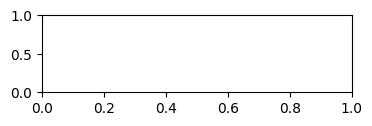

In [ ]:
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/cricket_project"
chase_df = pd.read_csv(FOLDER + "/chase_df.csv")
TRAIN_END = 2023
FEATURES = ["runs_left", "balls_left", "wickets_left", "crr", "rrr"]
LABEL = "chasing_won"
assert not (set(train_df["match_id"]) & set(test_df["match_id"]))
print(X_train.shape, X_test.shape)
train_df = chase_df[chase_df["year"] <= TRAIN_END]
test_df = chase_df[chase_df["year"] > TRAIN_END]
X_train, y_train = train_df[FEATURES], train_df[LABEL]
X_test, y_test = test_df[FEATURES], test_df[LABEL]

In [22]:
print(X_train.shape)
X_train.describe().round(2)

(112894, 5)


,runs_left,balls_left,wickets_left,crr,rrr
count,112894.00,112894.00,112894.00,112894.00,112894.00
mean,94.26,63.12,7.54,7.51,10.80
std,49.90,33.17,2.13,2.35,13.43
min,1.00,1.00,1.00,0.00,0.08
25%,55.00,35.00,6.00,6.32,7.29
50%,93.00,64.00,8.00,7.53,9.00
75%,132.00,92.00,9.00,8.76,11.11
max,264.00,120.00,10.00,60.00,792.00


In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
print("model trained")

model trained


In [24]:
pred_train = model.predict(X_train)
pred_test = model.predict(X_test)
print("train accuracy:", round((pred_train == y_train).mean(), 3))
print("test accuracy:", round((pred_test == y_test).mean(), 3))
print("baseline:", round((y_test == y_train.mode()[0]).mean(), 3))

train accuracy: 0.782
test accuracy: 0.81
baseline: 0.534


In [25]:
proba = model.predict_proba(X_test)[:, 1]
check = test_df[["runs_left", "balls_left", "wickets_left", "rrr"]].head(8).copy()
check["win_prob"] = proba[:8].round(3)
check["actual"] = y_test.head(8).values
check

,runs_left,balls_left,wickets_left,rrr,win_prob,actual
49912,170.0,119,10,8.571429,0.699,1
49913,170.0,118,10,8.644068,0.532,1
49914,170.0,117,10,8.717949,0.467,1
49915,170.0,116,10,8.793103,0.432,1
49916,166.0,115,10,8.660870,0.519,1
49917,166.0,114,10,8.736842,0.489,1
49918,162.0,113,10,8.601770,0.558,1
49919,161.0,112,10,8.625000,0.553,1


In [26]:
lr = model.named_steps["logisticregression"]
coef = pd.Series(lr.coef_[0], index=FEATURES).sort_values()
coef.round(3)

,0
rrr,-3.912
runs_left,-1.418
crr,0.135
balls_left,0.249
wickets_left,1.089


Need 30 off 24 balls, 7 wickets left: 0.886
Need 60 off 12 balls, 5 wickets left: 0.001
Need 10 off 30 balls, 3 wickets left: 0.912
Need 90 off 60 balls, 8 wickets left: 0.661


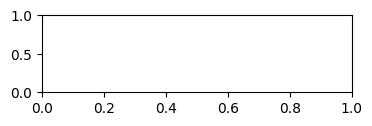

In [27]:
def win_prob(target, runs_left, balls_left, wickets_left):
  balls_bowled = 120 - balls_left
  runs_scored = target - runs_left
  crr = runs_scored * 6 / balls_bowled if balls_bowled > 0 else 0
  rrr = runs_left * 6 / balls_left
  row = pd.DataFrame([[runs_left, balls_left, wickets_left, crr, rrr]],
                   columns=FEATURES)
  return round(model.predict_proba(row)[0, 1], 3)
print("Need 30 off 24 balls, 7 wickets left:", win_prob(180, 30, 24, 7))
print("Need 60 off 12 balls, 5 wickets left:", win_prob(180, 60, 12, 5))
print("Need 10 off 30 balls, 3 wickets left:", win_prob(180, 10, 30, 3))
print("Need 90 off 60 balls, 8 wickets left:", win_prob(180, 90, 60, 8))

In [28]:
import os
import joblib
joblib.dump(model, FOLDER + "/model_logreg.joblib")
print(os.listdir(FOLDER))

['ipl_all_balls_v2.csv', 'chase_df.csv', 'model_logreg.joblib']


In [29]:
import pandas as pd
from google.colab import drive
drive.mount("/content/drive")
FOLDER = "/content/drive/MyDrive/cricket_project"
chase_df = pd.read_csv(FOLDER + "/chase_df.csv")
TRAIN_END = 2023
FEATURES = ["runs_left", "balls_left", "wickets_left", "crr", "rrr"]
LABEL = "chasing_won"
train_df = chase_df[chase_df["year"] <= TRAIN_END]
test_df = chase_df[chase_df["year"] > TRAIN_END]
X_train, y_train = train_df[FEATURES], train_df[LABEL]
X_test, y_test = test_df[FEATURES], test_df[LABEL]
assert not (set(train_df["match_id"]) & set(test_df["match_id"]))
print(X_train.shape, X_test.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(112894, 5) (23814, 5)


In [30]:
import os
import joblib
import numpy as np
import matplotlib.pyplot as plt
model = joblib.load(FOLDER + "/model_logreg.joblib")
proba = model.predict_proba(X_test)[:, 1]
print(len(proba), len(y_test))

23814 23814


In [31]:
from sklearn.metrics import accuracy_score, log_loss, roc_auc_score
const = np.full(len(y_test), y_train.mean())
base_ll = log_loss(y_test, const)
model_ll = log_loss(y_test, proba)
model_auc = roc_auc_score(y_test, proba)
base_acc = (y_test == y_train.mode()[0]).mean()
model_acc = accuracy_score(y_test, proba >= 0.5)
print("log loss  | constant:", round(base_ll, 4), "| model:", round(model_ll, 4))
print("AUC       | constant: 0.5    | model:", round(model_auc, 4))
print("accuracy  | baseline:", round(base_acc, 4), "| model:", round(model_acc, 4))

log loss  | constant: 0.6911 | model: 0.4069
AUC       | constant: 0.5    | model: 0.9167
accuracy  | baseline: 0.5336 | model: 0.8099


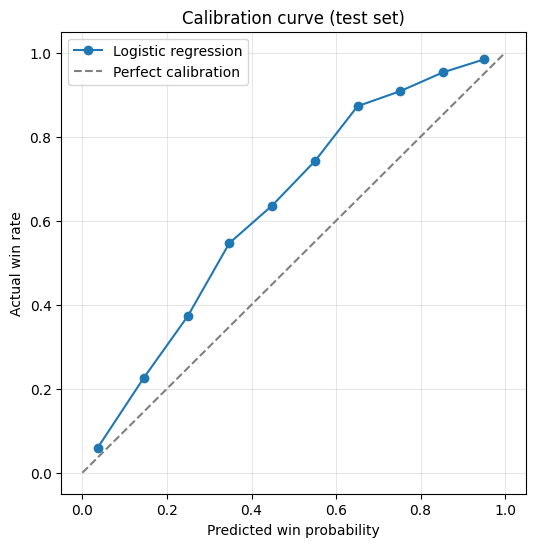

In [32]:
from sklearn.calibration import calibration_curve
frac_pos, mean_pred = calibration_curve(y_test, proba, n_bins=10)
plt.figure(figsize=(6, 6))
plt.plot(mean_pred, frac_pos, marker="o", label="Logistic regression")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
plt.title("Calibration curve (test set)")
plt.xlabel("Predicted win probability")
plt.ylabel("Actual win rate")
plt.grid(alpha=0.3)
plt.legend()
plt.savefig(FOLDER + "/chart5_calibration_logreg.png", dpi=150, bbox_inches="tight")
plt.show()

In [33]:
phase = pd.cut(test_df["balls_left"], bins=[0, 30, 60, 90, 120],
               labels=["Overs 16-20", "Overs 11-15", "Overs 6-10", "Overs 1-5"])
res = []
for name in ["Overs 1-5", "Overs 6-10", "Overs 11-15", "Overs 16-20"]:
  m = (phase == name).values
  res.append({"phase": name,
              "rows": int(m.sum()),
              "log_loss": round(log_loss(y_test[m], proba[m]), 3),
              "auc": round(roc_auc_score(y_test[m], proba[m]), 3)})
pd.DataFrame(res)

,phase,rows,log_loss,auc
0,Overs 1-5,6329,0.583,0.858
1,Overs 6-10,6405,0.419,0.910
2,Overs 11-15,6302,0.343,0.935
3,Overs 16-20,4778,0.241,0.970


In [34]:
results = pd.DataFrame([
    {"model": "Constant (train mean)", "log_loss": round(base_ll, 4),
     "auc": 0.5, "accuracy": round(base_acc, 4)},
      {"model": "Logistic regression", "log_loss": round(model_ll, 4),
       "auc": round(model_auc, 4), "accuracy": round(model_acc, 4)},
])
results.to_csv(FOLDER + "/results.csv", index=False)
results

,model,log_loss,auc,accuracy
0,Constant (train mean),0.6911,0.5000,0.5336
1,Logistic regression,0.4069,0.9167,0.8099


In [36]:
from google.colab import sheets
sheet = sheets.InteractiveSheet(df=results)

https://docs.google.com/spreadsheets/d/1TSbFXB22mfRDnemrc8b3i8r5uU6onZDxPdBH3Gsbdwo/edit#gid=0
